In [1]:
import os 
import pandas as pd
import numpy as np
import re
from sklearn.impute import KNNImputer
import seaborn as sns


Process main ephys feature file

In [2]:
metadata = pd.read_csv('/root/capsule/data/human/metadata/20260807/human_metadata.csv')
ephys = pd.read_csv('/root/capsule/data/human/electrophysiology/features/20260807/temp/patchseq_results_23June2026(combine_ephys).csv')

ephys_feature_batch_alignment = pd.read_csv('/root/capsule/data/human/electrophysiology/features/20260807/ephys_feature_map.csv')
old_ephys_feature_rename = pd.read_csv('/root/capsule/data/formatting_dicts/archive/ephys_feature_rename.csv')


In [3]:
ephys.head(3)

,cell_specimen_name,type,new_ephys,fx_count,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,...,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate_hero,mean_isi_hero,adapt_mean,isi_adapt_ratio,trough_slowdeltav_rheo,combined_ap_height,first_isi_inv_hero
0,H18.03.010.11.10.07,L4 IT_2,True,24,0.400119,0.125828,0.014959,-81.281525,160.0,0.114194,...,-84.550910,-51.781254,-49.218750,7.0,0.137123,0.125243,5.520161,-2.562504,86.812504,33.692722
1,H22.26.433.11.08.01.03,L4 IT_2,True,18,NaN,NaN,0.163456,-55.685322,90.0,0.006966,...,-84.409636,-50.218754,-41.687504,1.0,NaN,NaN,NaN,-8.531250,88.000006,NaN
2,H18.03.010.11.10.02,L4 IT_2,True,22,NaN,NaN,0.095969,-67.354050,100.0,0.117143,...,-71.561415,-49.781250,-49.000004,7.0,0.146013,0.058743,2.128923,-0.781246,84.812504,12.987013


In [4]:
ephys = ephys.rename(columns={'type':'cluster_label_Hierarchical'})

In [5]:
ephys = ephys[ephys['new_ephys'] == True]
assert len(ephys) == len(metadata[metadata.Electrophysiology == True]), "The number of ephys cells is not consistent between datasets"

In [6]:
ephys = metadata[['cell_specimen_name', 'cell_id', 'subclass_label_Hierarchical','Electrophysiology','depth_from_pia_norm']].merge(ephys, how='inner', on='cell_specimen_name')

assert ~ephys.Electrophysiology.isna().any(), "Not all cells have Ephys"
assert ~ephys.new_ephys.isna().any(), "Not all cells have Ephys"

ephys['cell_id'] = ephys['cell_id'].astype(int)
ephys.drop(columns=["new_ephys", "fx_count", 'cell_specimen_name', 'Electrophysiology'], inplace=True)

#reorder ttype column
col = ephys.pop(ephys.columns[3])
ephys.insert(2, col.name, col)

ephys.head(3)

,cell_id,subclass_label_Hierarchical,cluster_label_Hierarchical,depth_from_pia_norm,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,...,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate_hero,mean_isi_hero,adapt_mean,isi_adapt_ratio,trough_slowdeltav_rheo,combined_ap_height,first_isi_inv_hero
0,1371204672,L5/6 NP,L2/3 IT_1,NaN,0.394056,0.456929,0.250280,-61.224491,70.000000,0.225,...,-61.781884,-40.781250,-39.281250,12.0,0.056978,-0.059943,0.414378,-1.500000,70.593750,14.940983
1,798173253,L4 IT,L2/3 IT_1,0.454944,NaN,NaN,0.179292,-63.063919,29.999998,0.375,...,-95.253533,-41.906254,-41.424999,21.0,0.045778,0.189489,4.632530,-0.481255,88.450003,93.109870
2,798204000,L5 IT,L6b_3,0.539167,NaN,NaN,0.143060,-65.203545,29.999998,0.295,...,-73.789838,-56.068752,-50.050003,14.0,0.069225,0.082776,7.995979,-6.018749,77.956257,103.092783


In [7]:
ephys.shape

(1044, 28)

In [8]:
def normalize_new(x):
    return (
        re.sub(r'_rheo$', '', x)
        .replace('_hero', '')
        .replace('updown', 'upstroke_downstroke')
        .replace('cell_id', 'specimen_id')
    )

ephys.rename(columns=normalize_new, inplace=True)
ephys.set_index('specimen_id', inplace=True)
ephys.head(3)

,subclass_label_Hierarchical,cluster_label_Hierarchical,depth_from_pia_norm,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,combined_input_resistance_SS,...,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate,mean_isi,adapt_mean,isi_adapt_ratio,trough_slowdeltav,combined_ap_height,first_isi_inv
specimen_id,,,,,,,,,,,,,,,,,,,,,
1371204672,L5/6 NP,L2/3 IT_1,NaN,0.394056,0.456929,0.250280,-61.224491,70.000000,0.225,176.366650,...,-61.781884,-40.781250,-39.281250,12.0,0.056978,-0.059943,0.414378,-1.500000,70.593750,14.940983
798173253,L4 IT,L2/3 IT_1,0.454944,NaN,NaN,0.179292,-63.063919,29.999998,0.375,277.982295,...,-95.253533,-41.906254,-41.424999,21.0,0.045778,0.189489,4.632530,-0.481255,88.450003,93.109870
798204000,L5 IT,L6b_3,0.539167,NaN,NaN,0.143060,-65.203545,29.999998,0.295,212.945284,...,-73.789838,-56.068752,-50.050003,14.0,0.069225,0.082776,7.995979,-6.018749,77.956257,103.092783


In [9]:
new_ephys_feature_rename = old_ephys_feature_rename.merge(ephys_feature_batch_alignment, how='left', left_on='old_feature_name', right_on='old_column')[['normalized_name', 'new_feature_name']].dropna()
new_ephys_feature_rename.rename(columns={'normalized_name': 'old_feature_name'}, inplace=True)
#add new feature
new_ephys_feature_rename.loc[(len(new_ephys_feature_rename)+1)] = {
    "old_feature_name": "first_isi_inv",
    "new_feature_name": "Initial firing frequency",
}
#update a feature name
new_ephys_feature_rename["new_feature_name"] = new_ephys_feature_rename["new_feature_name"].replace({
    "Rheobase": "Rheobase current"
})
#remove whitespace from front/end of new feature names
new_ephys_feature_rename["new_feature_name"] = (
    new_ephys_feature_rename["new_feature_name"].str.strip()
)
new_ephys_feature_rename

,old_feature_name,new_feature_name
0,combined_upstroke_downstroke_ratio,AP up/down ratio
1,combined_width,AP width (ms)
2,combined_upstroke,AP ustroke
3,combined_downstroke,AP downstroke
4,combined_sag,Sag
5,combined_baseline,Resting membrane potential (RMP)
6,combined_input_resistance_SS,Input resistance
7,combined_tau,Tau
8,combined_ap_peak,AP peak
9,combined_ap_height,AP height


In [10]:
new_ephys_feature_rename.to_csv('/root/capsule/data/formatting_dicts/ephys_feature_rename.csv', index=False)
ephys.to_csv('/root/capsule/data/human/electrophysiology/features/20260807/ephys_features.csv')

KNN impute the missing ephys features per subclass

In [11]:
# Impute within each subclass 

# Specify the subset of columns to impute
columns_to_impute = [x for x in ephys.columns if not x.endswith('label_Hierarchical')]

<Axes: ylabel='specimen_id'>

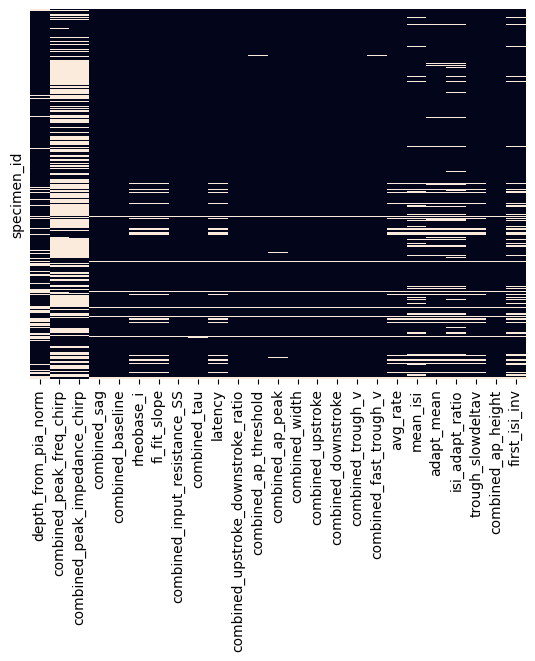

In [12]:
#before (plot missingness as boolean)
sns.heatmap(
    ephys[columns_to_impute].isna(),
    cbar=False,
    yticklabels=False
)

In [13]:
def impute_group(group):
    # Adjust n_neighbors if group is smaller than 100 cells
    n_neighbors = min(100, len(group))
    local_imputer = KNNImputer(n_neighbors=n_neighbors, weights="uniform")
    
    X = group[columns_to_impute]    
    imputed = local_imputer.fit_transform(X)

    return pd.DataFrame(imputed, index=group.index, columns=columns_to_impute)

# Apply groupwise imputation
ephys[columns_to_impute] = (ephys.groupby("subclass_label_Hierarchical", group_keys=False).apply(impute_group))

<Axes: ylabel='specimen_id'>

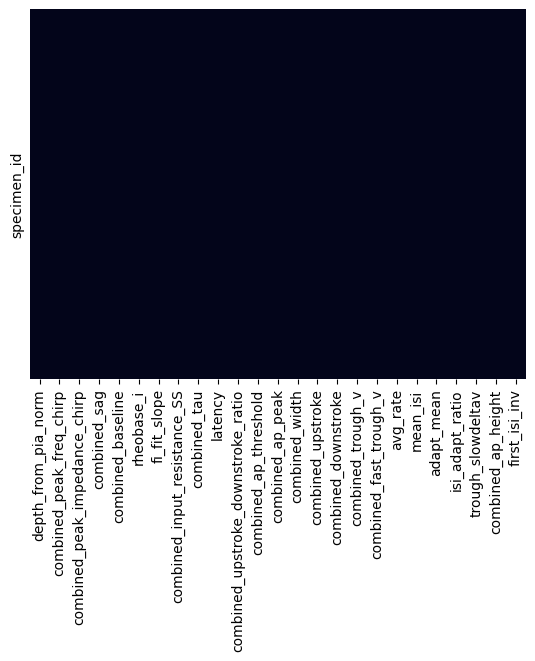

In [14]:
#after (plot missingness as boolean)
sns.heatmap(
    ephys[columns_to_impute].isna(),
    cbar=False,
    yticklabels=False
)

In [15]:
ephys.to_csv('/root/capsule/data/human/electrophysiology/features/20260807/ephys_features_imputed.csv')

FI data

In [16]:
old_fi_data = pd.read_csv('/root/capsule/data/human/electrophysiology/fi_features/20260807/temp/20251008_ephys_fi_curve_data.csv')
new_fi_data = pd.read_csv('/root/capsule/data/human/electrophysiology/fi_features/20260807/temp/features_exc_human_July2026_additional.csv')

old_fi_data = old_fi_data.rename(columns=lambda col: col.replace('nwg_', ''))
old_fi_data.drop(columns=['ephys', 'feature_count', 'specimen_name', 'subclass_label_Hierarchical'], inplace=True)

missing_cols_in_new_fi = [
 'avg_rate_10_long_square',
 'avg_rate_8_long_square',
 'stimulus_amplitude_10_long_square',
 'stimulus_amplitude_8_long_square']

new_fi_data[missing_cols_in_new_fi] = np.nan

new_fi_data = new_fi_data[old_fi_data.columns.tolist()]

fi_data = pd.concat([new_fi_data, old_fi_data], ignore_index=True)

In [17]:
old_fi_data.shape

(959, 23)

In [18]:
ephys

,subclass_label_Hierarchical,cluster_label_Hierarchical,depth_from_pia_norm,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,combined_input_resistance_SS,...,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate,mean_isi,adapt_mean,isi_adapt_ratio,trough_slowdeltav,combined_ap_height,first_isi_inv
specimen_id,,,,,,,,,,,,,,,,,,,,,
1371204672,L5/6 NP,L2/3 IT_1,0.643582,0.394056,0.456929,0.250280,-61.224491,70.000000,0.225000,176.366650,...,-61.781884,-40.781250,-39.281250,12.000000,0.056978,-0.059943,0.414378,-1.500000,70.593750,14.940983
798173253,L4 IT,L2/3 IT_1,0.454944,0.982775,0.506204,0.179292,-63.063919,29.999998,0.375000,277.982295,...,-95.253533,-41.906254,-41.424999,21.000000,0.045778,0.189489,4.632530,-0.481255,88.450003,93.109870
798204000,L5 IT,L6b_3,0.539167,1.394376,0.552058,0.143060,-65.203545,29.999998,0.295000,212.945284,...,-73.789838,-56.068752,-50.050003,14.000000,0.069225,0.082776,7.995979,-6.018749,77.956257,103.092783
798338649,L2/3 IT,L5 IT_6,0.221690,1.336828,0.185553,0.079290,-61.298718,80.000000,0.130000,123.051297,...,-90.290744,-46.375004,-42.700005,6.000000,0.151956,0.168514,6.171806,-3.674999,93.150002,31.505986
797978191,L4 IT,L4 IT_2,0.422805,0.900268,0.483577,0.088374,-63.363297,29.999998,0.240000,276.618286,...,-65.047050,-49.275002,-48.599998,15.000000,0.068444,0.212298,3.512346,-0.675003,90.737503,54.171181
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1451264809,L2/3 IT,L2/3 IT_6,0.175785,0.400122,0.141406,0.080567,-72.498329,110.000000,0.091964,117.364317,...,-79.080525,-58.906254,-50.500000,3.000000,0.363455,0.083558,1.638106,-8.406254,79.500004,3.597381
1451264934,L2/3 IT,L2/3 IT_6,0.169007,1.000306,0.081373,0.064607,-70.303541,137.597499,0.111585,110.693185,...,-87.027100,-50.653957,-47.939298,7.150000,0.143787,0.128100,7.119004,-3.063659,82.479810,38.533990
1447135669,L5 IT,L5 IT_2,0.515030,1.317426,0.753412,0.150063,-63.912165,67.212339,0.183890,184.305049,...,-84.066139,-52.759107,-49.092232,8.871795,0.117237,0.105908,4.672505,-3.894671,80.831259,38.248797


In [19]:
new_fi_data.shape

(14, 23)

In [20]:
fi_data = metadata[['cell_id', 'subclass_label_Hierarchical', 'Electrophysiology']].rename(
    columns={'cell_id': 'specimen_id'}).merge(fi_data, how='right', on='specimen_id')

fi_data = fi_data[(fi_data['Electrophysiology'] == True) & \
                  (fi_data['specimen_id'].isin(ephys.index))]

fi_data

,specimen_id,subclass_label_Hierarchical,Electrophysiology,avg_rate_0_long_square,avg_rate_1_long_square,avg_rate_10_long_square,avg_rate_2_long_square,avg_rate_3_long_square,avg_rate_4_long_square,avg_rate_5_long_square,...,stimulus_amplitude_3_long_square,stimulus_amplitude_5_long_square,stimulus_amplitude_7_long_square,stimulus_amplitude_9_long_square,stimulus_amplitude_1_long_square,stimulus_amplitude_2_long_square,stimulus_amplitude_4_long_square,stimulus_amplitude_6_long_square,stimulus_amplitude_8_long_square,stimulus_amplitude_10_long_square
0,7.983386e+08,L2/3 IT,True,1.0,NaN,NaN,4.0,NaN,6.0,NaN,...,NaN,NaN,NaN,NaN,NaN,100.0,120.0,140.0,NaN,NaN
1,9.331946e+08,L6 CT,True,1.0,NaN,NaN,NaN,5.0,NaN,7.0,...,160.0,180.0,200.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.245582e+09,L5 IT,True,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.294106e+09,L5 ET,True,2.0,NaN,NaN,NaN,4.0,NaN,5.0,...,100.0,120.0,140.0,160.0,NaN,NaN,NaN,NaN,NaN,NaN
5,1.417481e+09,L2/3 IT,True,1.0,NaN,NaN,NaN,1.0,NaN,4.0,...,180.0,200.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,1.296492e+09,L6 CT,True,1.0,1.0,NaN,1.0,1.0,NaN,2.0,...,450.0,470.0,490.0,510.0,430.0,440.0,NaN,NaN,NaN,NaN
969,9.199898e+08,L2/3 IT,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
970,1.310108e+09,L6 CT,True,1.0,NaN,NaN,NaN,1.0,NaN,1.0,...,499.0,520.0,540.0,560.0,NaN,NaN,NaN,NaN,NaN,NaN
971,5.914557e+08,L4 IT,True,1.0,NaN,NaN,NaN,1.0,2.0,NaN,...,120.0,NaN,NaN,NaN,NaN,NaN,130.0,150.0,NaN,NaN


In [21]:
fi_data.to_csv('/root/capsule/data/human/electrophysiology/fi_features/20260807/ephys_fi_curve_data.csv')

Sparse PCA

In [22]:
old_spca = pd.read_csv('/root/capsule/data/human/electrophysiology/sparce_pca/20260807/temp/sparse_pca_components_exc_human_May2025_flex.csv', index_col=0)
new_spca = pd.read_csv('/root/capsule/data/human/electrophysiology/sparce_pca/20260807/temp/sparse_pca_components_exc_human_July2026_flex.csv', index_col=0)

new_spca = new_spca[new_spca.index.isin(ephys.index)]


In [23]:
old_spca.shape

(805, 47)

In [24]:
new_spca.shape

(810, 46)

In [25]:
old_spca.head(3)

,0,1,2,3,4,5,6,7,8,9,...,37,38,39,40,41,42,43,44,45,46
1415831256,-1.320187,0.106383,-0.412445,-0.683360,1.342867,-0.158726,-0.650397,0.580827,0.879588,-0.590958,...,-0.188427,0.385906,-0.93579,0.098479,-0.054700,0.519373,-0.916815,-0.900241,-0.126121,-0.062038
1414830614,1.009837,1.667734,0.266233,-0.370542,-0.823339,0.567014,-1.291857,1.203542,-0.051408,2.077263,...,1.358876,-0.395581,0.96576,-1.616826,-1.426429,-1.246547,0.812728,0.285468,0.553528,0.875356
1414810063,1.073532,-2.484278,1.399630,-3.096828,0.657820,-3.444365,1.317971,-1.246983,-2.162846,1.593983,...,1.246954,-2.672848,1.57047,-2.009161,-2.013239,-1.823578,-0.434910,-0.327396,1.122330,-0.469724


In [26]:
new_spca.head(3)

,0,1,2,3,4,5,6,7,8,9,...,36,37,38,39,40,41,42,43,44,45
1415831256,-1.329647,0.098497,-0.411435,-0.682072,1.344900,-0.178645,-0.639269,0.570844,0.878102,-0.629751,...,-0.189115,0.386762,-0.942226,0.109349,-0.042232,0.516692,-0.910209,-0.916639,-0.052413,-0.075733
1414830614,1.003653,1.657352,0.248965,-0.370042,-0.822600,0.525085,-1.246792,1.197478,-0.027342,2.031619,...,1.360578,-0.393532,0.958604,-1.609498,-1.437216,-1.244540,0.828201,0.301159,0.505423,0.891075
1414810063,1.070269,-2.474873,1.407403,-3.083019,0.701924,-3.419754,1.398278,-1.260051,-2.144473,1.702936,...,1.248354,-2.665176,1.563143,-2.022118,-2.005042,-1.823494,-0.413485,-0.246361,1.103773,-0.468661


In [27]:
set(old_spca.columns) - set(new_spca.columns)

{'46'}

In [28]:
new_spca.to_csv('/root/capsule/data/human/electrophysiology/sparce_pca/20260807/ephys_sparse_pca.csv')